# **HOMEWORK 2: CAUTION! CONTENTS ARE HOT**


---------------------
#### **DATASET DESCRIPTION**

The [NCEI/WDS Global Significant Volcanic Eruptions Database](https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.ngdc.mgg.hazards:G10147) is a very comprehensive collection of +600 volcanic eruptions dating from 4360 BC to the present. Due to the nature of this assignment, we will be dealing with relatively newer volcanoes (in which some are still obviously still older than anyone on Earth currently). Each eruption in the database is classified as significant if it meets one or more criteria, such as causing fatalities, incurring **damage on property** (**+$1 million**), reaching a **Volcanic Explosivity Index (VEI)** of **6 or higher**, generating a tsunami, or being linked to a significant earthquake. The VEI is a scale that measures the explosiveness of volcanic eruptions, providing insight into the magnitude and potential consequences of the eruptions. The database includes detailed information on the location, type of volcano, last known eruption, VEI, casualties, property damage, and much more.
![volcano](https://wikitravel.org/upload/shared//9/99/Volcano_de_Fuego_Banner.jpg)

#### **Objective of the Assignment:**

**We are going to dive straight into these volcanoes (well... their dataset), to swim our way into Pandas and SQL proficiency!**

You will find the [Pandas Documentation](https://pandas.pydata.org/docs/user_guide/index.html) helpful. There are also some helpful links to guide you along the way! Don't get burned

---------------------

### **DO NOT REMOVE ANY PART OF ANY OF THE QUESTIONS OR YOU LOSE CREDIT**
### *No Hardcoding either*  
### **REMEMBER TO SHOW ALL CODE OUTPUT (NO CREDIT OTHERWISE)**

### **Part 1: Maintenance (25 POINTS TOTAL)**
First, we're going to familiarize ourselves with the process. As in most languages, Python looks best when its modules are imported first before any other code is written

In [3]:
# Make sure these code blocks run properly and that you have properly installed the appropriate modules required.
import pandas as pd
import requests
# import other libraries here

# Don't remove this
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

As you may have noticed, there's another library aside from Pandas called "[requests](https://requests.readthedocs.io/en/latest/)." **The requests library allows you to send HTTP requests to a server, retrieve the content, and process it at ease.** It's very beginner friendly for those attempting to get into webscraping (super important for collecting and creating datasets). We also recommend looking into [BeautifulSoup](https://beautiful-soup-4.readthedocs.io/en/latest/) (yeah, soup LOL), another wonderful library that can be paired with the requests library for webscraping.

As shown below, sometimes specific websites require specific headers in order to process a request to access the data.

To check if a request was processed successfully, use the [status_code](https://requests.readthedocs.io/en/latest/api/) function to see if the process returned 200.

In [4]:
# API URL and headers in case request gets denied.
api_url = "https://www.ngdc.noaa.gov/hazel/hazard-service/api/v1/volcanoes"

headers = {
    'accept': '*/*'
}

#### **TASK 1.0: Cute Webscraping (5 points)**
To make our cute webscraper we need to **create a GET request** using the relevant information given above.

This particular dataset NOAA returns data from the API as ***json*** when a user makes a request. The json data has a particular format, so we will extract our needed information only from the field called **items** to make a dataframe.

**After properly scraping the data, name this dataframe** ***df***

**Save this dataframe into a CSV file named 'volcanoes.csv'**

**You won't need to run this more than once**

In [12]:
volcano_data = requests.get(api_url)
data = volcano_data.json()
df = pd.DataFrame(data["items"])
df.head()

,id,year,month,day,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,volcanoLocationNum,name,location,country,latitude,longitude,elevation,morphology,agent,deathsTotal,deathsAmountOrderTotal,damageAmountOrderTotal,significant,publish,eruption,status,timeErupt,vei,deathsAmountOrder,damageAmountOrder,housesDestroyedAmountOrderTotal,deaths,injuries,injuriesAmountOrder,injuriesTotal,injuriesAmountOrderTotal,housesDestroyedAmountOrder,housesDestroyed,housesDestroyedTotal,missingAmountOrder,missingAmountOrderTotal,missing,missingTotal,damageMillionsDollars,damageMillionsDollarsTotal
0,1,1169,2.0,4.0,2852.0,421.0,10106,211060,0101-06=,Etna,Italy,Italy,37.748,14.999,3357,Stratovolcano,"S,W",16000.0,4.0,4.0,True,False,True,Historical,D1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1329,7.0,15.0,NaN,NaN,10106,211060,0101-06=,Etna,Italy,Italy,37.748,14.999,3357,Stratovolcano,I,NaN,3.0,NaN,True,False,True,Historical,D1,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1883,3.0,NaN,NaN,NaN,30301,233010,0303-01=,Karthala,Indian O-W,Comoros,-11.750,43.380,2361,Shield volcano,L,NaN,3.0,3.0,True,False,True,Historical,D1,2.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1888,3.0,13.0,1175.0,NaN,50107,251070,0501-07=,Ritter Island,New Guinea-NE of,Papua New Guinea,-5.519,148.115,75,Stratovolcano,W,NaN,4.0,3.0,True,False,True,Historical,D1,2.0,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,1850,NaN,NaN,NaN,NaN,50214,252140,0502-14=,Rabaul,New Britain-SW Pac,Papua New Guinea,-4.246,152.194,688,Pyroclastic shield,T,NaN,3.0,NaN,True,False,True,Historical,D1,2.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### **TASK 1.1: 1 Liner Thingz (3 points)**

We need to get an idea of what this dataset is going to look. In order to do that, let's take a look at some of the most basic things our dataframe has.

**Read the directions carefully and code your answer with only one line of code.**

***CAN'T USE LOOPS. DO NOT DISPLAY THE DATAFRAME, JUST YOUR CODE OUTPUT HERE.***

**1.1.1:** *In one line of code and **using only one function**, show how many **total datapoints and features** there are in the dataframe **together**.*

In [14]:
shape = df.shape
print(f"Total data points: {df.shape[0]}")
print(f"Total features: {df.shape[1]}")

Total data points: 200
Total features: 43


**1.1.2:** *In one line of code, list the **names** of all the **features** in the dataframe.*

In [17]:
df.columns.tolist()

['id',
 'year',
 'month',
 'day',
 'tsunamiEventId',
 'earthquakeEventId',
 'volcanoLocationId',
 'volcanoLocationNewNum',
 'volcanoLocationNum',
 'name',
 'location',
 'country',
 'latitude',
 'longitude',
 'elevation',
 'morphology',
 'agent',
 'deathsTotal',
 'deathsAmountOrderTotal',
 'damageAmountOrderTotal',
 'significant',
 'publish',
 'eruption',
 'status',
 'timeErupt',
 'vei',
 'deathsAmountOrder',
 'damageAmountOrder',
 'housesDestroyedAmountOrderTotal',
 'deaths',
 'injuries',
 'injuriesAmountOrder',
 'injuriesTotal',
 'injuriesAmountOrderTotal',
 'housesDestroyedAmountOrder',
 'housesDestroyed',
 'housesDestroyedTotal',
 'missingAmountOrder',
 'missingAmountOrderTotal',
 'missing',
 'missingTotal',
 'damageMillionsDollars',
 'damageMillionsDollarsTotal']

We won't be using some of the data because there is a lot of missing data.

**1.1.3:** *In one line of code, create a **new dataframe** called **new_df** that **contains all** the features of the **old** dataframe **except the following**:*

volcanoLocationNum, location, latitude, longitude, agent, significant,	publish,	eruption,	status, timeErupt, damageAmountOrder, damageAmountOrderTotal, housesDestroyedAmountOrder,	housesDestroyedAmountOrderTotal, housesDestroyed,	housesDestroyedTotal,	missingAmountOrder,	missingAmountOrderTotal,	missing,	missingTotal, damageMillionsDollars, damageMillionsDollarsTotal, injuries, injuriesAmountOrder, injuriesTotal, injuriesAmountOrderTotal, deathsAmountOrderTotal, and deathsAmountOrder.



In [18]:
new_df = df.drop(columns=['volcanoLocationNum', 'location', 'latitude', 'longitude', 'agent', 'significant', 'publish', 'eruption', 'status', 'timeErupt', 'damageAmountOrder', 'damageAmountOrderTotal', 'housesDestroyedAmountOrder', 'housesDestroyedAmountOrderTotal', 'housesDestroyed', 'housesDestroyedTotal', 'missingAmountOrder', 'missingAmountOrderTotal', 'missing', 'missingTotal', 'damageMillionsDollars', 'damageMillionsDollarsTotal', 'injuries', 'injuriesAmountOrder', 'injuriesTotal', 'injuriesAmountOrderTotal', 'deathsAmountOrderTotal', 'deathsAmountOrder'], errors='ignore')

# KEEP THIS. It will display the whole dataframe.
new_df

,id,year,month,day,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,name,country,elevation,morphology,deathsTotal,vei,deaths
0,1,1169,2.0,4.0,2852.0,421.0,10106,211060,Etna,Italy,3357,Stratovolcano,16000.0,NaN,NaN
1,2,1329,7.0,15.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,3.0,NaN
2,3,1883,3.0,NaN,NaN,NaN,30301,233010,Karthala,Comoros,2361,Shield volcano,NaN,2.0,NaN
3,4,1888,3.0,13.0,1175.0,NaN,50107,251070,Ritter Island,Papua New Guinea,75,Stratovolcano,NaN,2.0,NaN
4,5,1850,NaN,NaN,NaN,NaN,50214,252140,Rabaul,Papua New Guinea,688,Pyroclastic shield,NaN,2.0,NaN
5,6,1832,11.0,1.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,2.0,NaN
6,7,1977,1.0,10.0,NaN,NaN,20303,223030,Nyiragongo,"Congo, DRC",3470,Stratovolcano,NaN,1.0,NaN
7,8,787,NaN,NaN,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,NaN,3.0,NaN
8,9,1779,8.0,8.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,NaN,3.0,NaN
9,10,1302,NaN,NaN,NaN,NaN,10103,211030,Ischia,Italy,789,Complex volcano,NaN,NaN,NaN


In [19]:
new_df.shape

(200, 15)

#### **TASK 1.2: 1 Liner Shenaniganz (7 points)**

We're going to tidy up the **new dataframe** a little more with some more advanced 1 liner code.

**Read the directions carefully and code your answer with only one line of code.**

**For this section, keep the method of display that is already in the box. Write your code as indicated.**

***YOU CAN'T USE ONE LINE LOOPS OR ANY KIND OF LOOP.***

**1.2.1:** *In one line of code, **discard any row** that contains **NaN** in **any one** of the columns indicating **time**.*

In [20]:
new_df = new_df.dropna(subset=["year","month","day"])

# KEEP THIS. It will display the whole dataframe.
new_df

,id,year,month,day,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,name,country,elevation,morphology,deathsTotal,vei,deaths
0,1,1169,2.0,4.0,2852.0,421.0,10106,211060,Etna,Italy,3357,Stratovolcano,16000.0,NaN,NaN
1,2,1329,7.0,15.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,3.0,NaN
3,4,1888,3.0,13.0,1175.0,NaN,50107,251070,Ritter Island,Papua New Guinea,75,Stratovolcano,NaN,2.0,NaN
5,6,1832,11.0,1.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,2.0,NaN
6,7,1977,1.0,10.0,NaN,NaN,20303,223030,Nyiragongo,"Congo, DRC",3470,Stratovolcano,NaN,1.0,NaN
8,9,1779,8.0,8.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,NaN,3.0,NaN
10,11,1907,8.0,4.0,NaN,NaN,201112,221112,Alayta,Ethiopia,1496,Shield volcano,NaN,2.0,NaN
11,12,1905,3.0,10.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,1.0,2.0,1.0
12,13,1986,7.0,24.0,NaN,NaN,10104,211040,Stromboli,Italy,924,Stratovolcano,1.0,2.0,1.0
13,14,1536,3.0,26.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,1.0,3.0,1.0


**1.2.2:** *In one line of code, **reset** the **index column** of the dataframe so that it has **1-based indexing**.*

In [21]:
new_df = new_df.reset_index(drop=True).set_index(pd.Index(range(1,len(new_df)+1)))

# KEEP THIS. It will display the whole dataframe.
new_df

,id,year,month,day,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,name,country,elevation,morphology,deathsTotal,vei,deaths
1,1,1169,2.0,4.0,2852.0,421.0,10106,211060,Etna,Italy,3357,Stratovolcano,16000.0,NaN,NaN
2,2,1329,7.0,15.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,3.0,NaN
3,4,1888,3.0,13.0,1175.0,NaN,50107,251070,Ritter Island,Papua New Guinea,75,Stratovolcano,NaN,2.0,NaN
4,6,1832,11.0,1.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,2.0,NaN
5,7,1977,1.0,10.0,NaN,NaN,20303,223030,Nyiragongo,"Congo, DRC",3470,Stratovolcano,NaN,1.0,NaN
6,9,1779,8.0,8.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,NaN,3.0,NaN
7,11,1907,8.0,4.0,NaN,NaN,201112,221112,Alayta,Ethiopia,1496,Shield volcano,NaN,2.0,NaN
8,12,1905,3.0,10.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,1.0,2.0,1.0
9,13,1986,7.0,24.0,NaN,NaN,10104,211040,Stromboli,Italy,924,Stratovolcano,1.0,2.0,1.0
10,14,1536,3.0,26.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,1.0,3.0,1.0


The **deathsTotal** and **deaths**  columns have approximations of the same data with alternating NaNs in each.

**1.2.3:** *In one line of code, make a **new column** called **'totalDeaths'** that takes the **max** of the values given between those* ***two*** *columns. If there is* ***NaN*** *in* ***one column*** *and a* ***numerical*** *value in the* ***other***, *it will ***take the numerical value***. ***Only*** if there are* ***NaNs*** *in* ***both*** *columns, the* ***new column will have NaN.***

In [22]:
new_df['totalDeaths'] = new_df['deathsTotal'].combine(new_df['deaths'], max)

# KEEP THIS. It will display the whole dataframe.
new_df

,id,year,month,day,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,name,country,elevation,morphology,deathsTotal,vei,deaths,totalDeaths
1,1,1169,2.0,4.0,2852.0,421.0,10106,211060,Etna,Italy,3357,Stratovolcano,16000.0,NaN,NaN,16000.0
2,2,1329,7.0,15.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,3.0,NaN,NaN
3,4,1888,3.0,13.0,1175.0,NaN,50107,251070,Ritter Island,Papua New Guinea,75,Stratovolcano,NaN,2.0,NaN,NaN
4,6,1832,11.0,1.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,NaN,2.0,NaN,NaN
5,7,1977,1.0,10.0,NaN,NaN,20303,223030,Nyiragongo,"Congo, DRC",3470,Stratovolcano,NaN,1.0,NaN,NaN
6,9,1779,8.0,8.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,NaN,3.0,NaN,NaN
7,11,1907,8.0,4.0,NaN,NaN,201112,221112,Alayta,Ethiopia,1496,Shield volcano,NaN,2.0,NaN,NaN
8,12,1905,3.0,10.0,NaN,NaN,10102,211020,Vesuvius,Italy,1281,Complex volcano,1.0,2.0,1.0,1.0
9,13,1986,7.0,24.0,NaN,NaN,10104,211040,Stromboli,Italy,924,Stratovolcano,1.0,2.0,1.0,1.0
10,14,1536,3.0,26.0,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,1.0,3.0,1.0,1.0


#### **TASK 1.3: Tailoring Time (10 Points)**
It's pretty obvious that the year, month, and day look pretty weird in the dataset. We're going to have to do some hardcore cleaning on the [time](https://pandas.pydata.org/docs/user_guide/timeseries.html). We will learn more about data cleaning in class soon, but here we will perform some basic data cleaning.

**We need to have only ONE column called** "***date***" **that contains the full date (YYYY-MM-DD), not separated into three columns.**

***Make sure there are no floating point values in the date and sort the data from most recent to least.***

***Remove the old columns and place the new column next to the 'id' column.***


**YOU CAN USE MULTIPLE LINES OF CODE BUT CAN'T USE LOOPS.**

**Note:** It is alright to have only a **maximum of 12 NaTs** for some dates that often go further back than the 1600s because the datetime module in Pandas has a limit (unless otherwise guided).

In [23]:
new_df['date'] = pd.to_datetime(new_df[['year','month','day']].astype(int).astype(str).agg('-'.join, axis=1), errors='coerce')
new_df = new_df.sort_values(by='date', ascending=False).drop(columns=['year', 'month', 'day'])
new_df.insert(1, 'date', new_df.pop('date'))

# KEEP THIS. It will display the whole dataframe.
new_df

,id,date,tsunamiEventId,earthquakeEventId,volcanoLocationId,volcanoLocationNewNum,name,country,elevation,morphology,deathsTotal,vei,deaths,totalDeaths
122,693,1996-08-10,NaN,NaN,70202,272020,Kanlaon,Philippines,2422,Stratovolcano,3.0,2.0,3.0,3.0
51,112,1994-11-22,NaN,NaN,60325,263250,Merapi,Indonesia,2910,Stratovolcano,66.0,3.0,66.0,66.0
155,933,1991-06-03,NaN,NaN,80210,282100,Unzendake,Japan,1483,Complex volcano,43.0,1.0,43.0,43.0
61,144,1990-02-10,NaN,NaN,60328,263280,Kelud,Indonesia,1730,Stratovolcano,35.0,4.0,35.0,35.0
93,486,1988-05-09,NaN,NaN,60509,265090,Banda Api,Pacific Ocean,596,Caldera,4.0,3.0,4.0,4.0
25,31,1987-04-17,NaN,NaN,10106,211060,Etna,Italy,3357,Stratovolcano,2.0,2.0,2.0,2.0
50,111,1986-12-31,NaN,NaN,60325,263250,Merapi,Indonesia,2910,Stratovolcano,1.0,2.0,1.0,1.0
9,13,1986-07-24,NaN,NaN,10104,211040,Stromboli,Italy,924,Stratovolcano,1.0,2.0,1.0,1.0
72,203,1985-05-10,NaN,NaN,60330,263300,Semeru,Indonesia,3657,Stratovolcano,70.0,3.0,70.0,70.0
135,739,1984-09-09,NaN,NaN,70303,273030,Mayon,Philippines,2462,Stratovolcano,1.0,3.0,1.0,1.0


### **Part 2: Volcanic Matryoshkas (30 POINTS TOTAL)**

Now, that most of the data has been tidied up. We will organize the data into more sizable pieces of information in order to extract useful information.

**2.1.1:** *(10 points here)*

**Use the groupby function in Pandas to create separate dataframes for each unique country.**

* Each table must only have the columns: 'date' 'country', 'name', and 'vei'

* Sort the dataframe of each country by highest to lowest 'vei'

**You MUST use the groupby function here.**

In [25]:
country_dfs = {country: group[['date','country','vei']].sort_values(by='vei', ascending=False) for country, group in new_df.groupby('country')}

country_dfs

{'Cameroon':          date   country  vei
 34 1984-08-15  Cameroon  NaN,
 'Comoros':          date  country  vei
 11 1904-02-25  Comoros  2.0,
 'Congo, DRC':          date     country  vei
 28 1912-12-03  Congo, DRC  3.0
 5  1977-01-10  Congo, DRC  1.0,
 'Ethiopia':          date   country  vei
 7  1907-08-04  Ethiopia  2.0
 36 1631-02-14  Ethiopia  NaN,
 'Greece':          date country  vei
 35 1926-01-23  Greece  2.0,
 'Indonesia':           date    country  vei
 80  1815-04-10  Indonesia  7.0
 78  1963-03-18  Indonesia  5.0
 108 1673-05-20  Indonesia  5.0
 59  1951-08-31  Indonesia  4.0
 107 1966-08-12  Indonesia  4.0
 44  1872-11-03  Indonesia  4.0
 58  1919-05-19  Indonesia  4.0
 60  1966-04-26  Indonesia  4.0
 61  1990-02-10  Indonesia  4.0
 94  1983-07-23  Indonesia  4.0
 43  1872-04-15  Indonesia  4.0
 116 1646-07-19  Indonesia  4.0
 117 1861-12-29  Indonesia  4.0
 53  1826-10-13  Indonesia  4.0
 40  1672-08-04  Indonesia  3.0
 103 1812-08-06  Indonesia  3.0
 75  1981-03-29  In

**2.1.2:** *(5 points here)*

**Using groupby again, print out the maximum 'vei' for each unique country.**

**You MUST use the groupby function here.**

* Print out your results in a format like the following: "Country: {country_name}, Highest VEI: {vei}"

In [26]:
for country, group in new_df.groupby('country'):
    print(f"Country:{country}, Highest VEI:{group['vei'].max()}")

Country:Cameroon, Highest VEI:nan
Country:Comoros, Highest VEI:2.0
Country:Congo, DRC, Highest VEI:3.0
Country:Ethiopia, Highest VEI:2.0
Country:Greece, Highest VEI:2.0
Country:Indonesia, Highest VEI:7.0
Country:Italy, Highest VEI:3.0
Country:Japan, Highest VEI:5.0
Country:New Zealand, Highest VEI:1.0
Country:Pacific Ocean, Highest VEI:4.0
Country:Papua New Guinea, Highest VEI:3.0
Country:Philippines, Highest VEI:4.0
Country:Taiwan, Highest VEI:2.0
Country:Tonga, Highest VEI:4.0


**2.1.3:** *(15 points here)*

Finally, we have ALMOST REACHED THE END!!
Since there is still quite a bit of missing data, we want to make use of what is still available.

A very powerful tool in Python's magnificent collection of libraries is its beautiful graphing tools.

Check out libraries such as [Seaborn](https://seaborn.pydata.org/) or [Matplotlib](https://matplotlib.org/stable/index.html) to create meaningful visualizations! **Your final task requires the use of these libraries**

**Based on the unique names of volcanos, filter names that have more than 3 datapoints under their name.**

* Make separate graphs for each volcano and plot their VEIs over time.

* Make sure to properly label all parts of the graph.

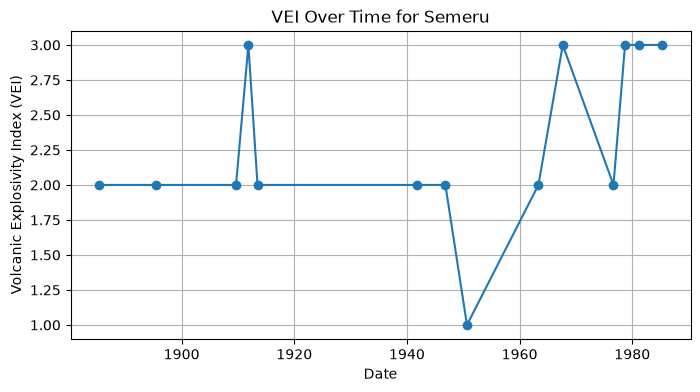

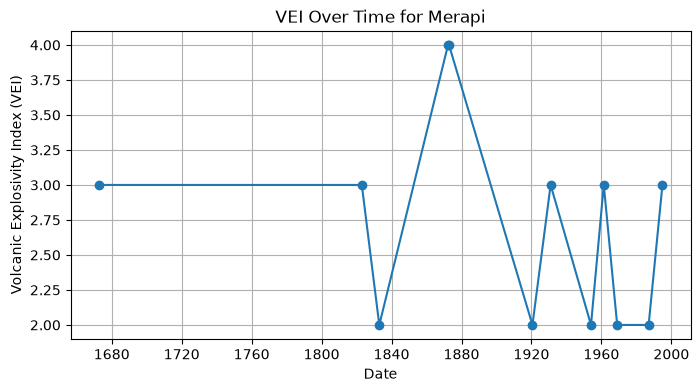

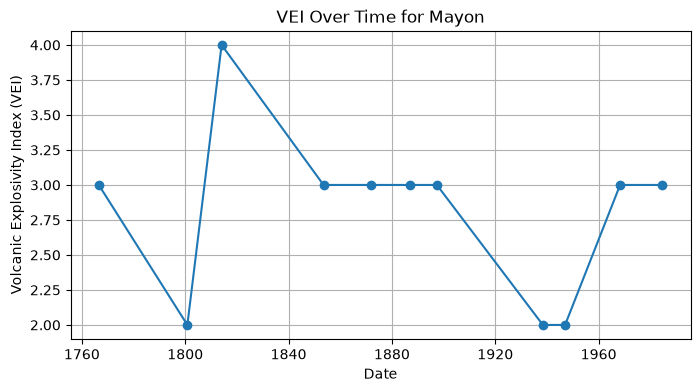

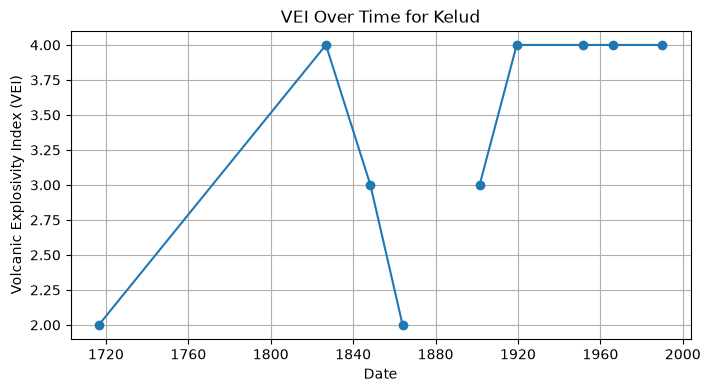

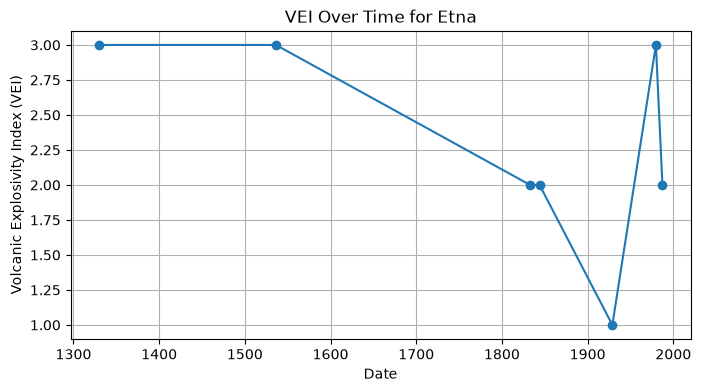

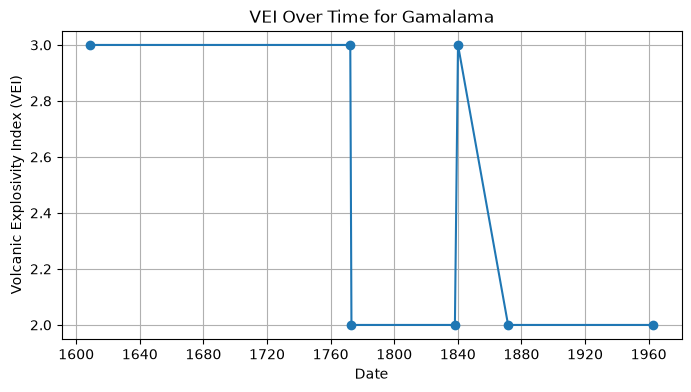

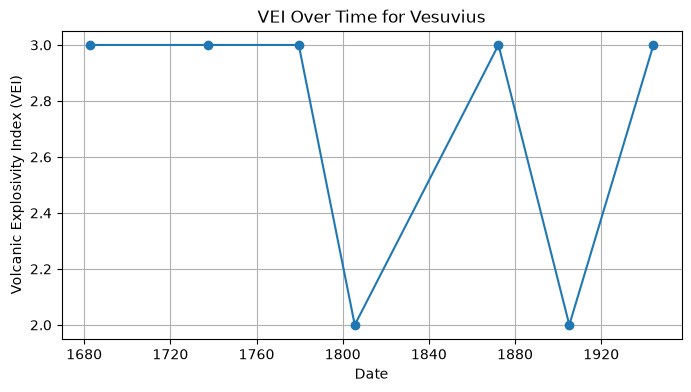

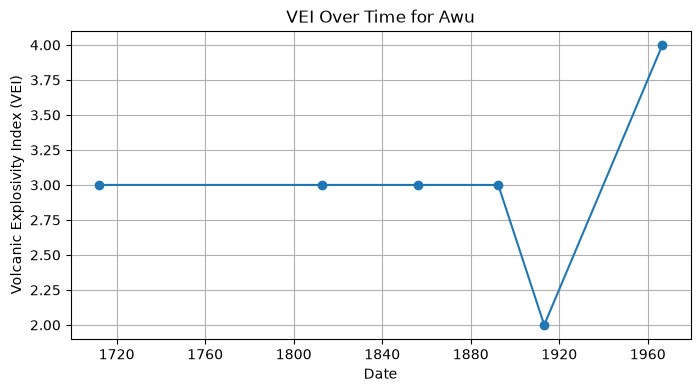

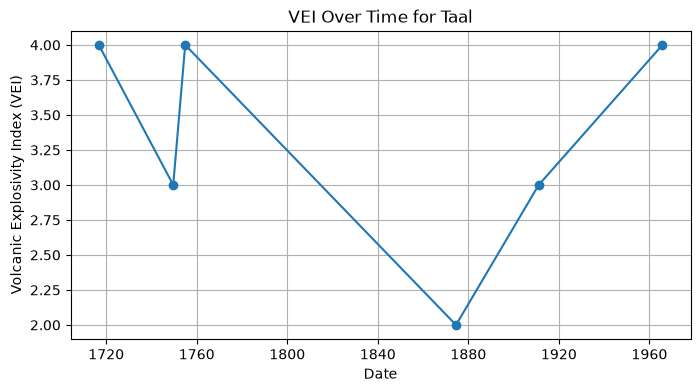

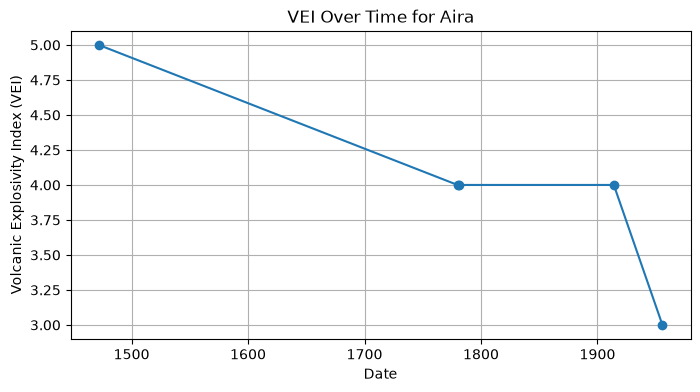

In [29]:
import matplotlib.pyplot as plt

volcano_counts = new_df['name'].value_counts()
filtered_volcanoes = volcano_counts[volcano_counts > 3].index

for volcano in filtered_volcanoes:
    data = new_df[new_df['name'] == volcano].sort_values(by='date')
    
    plt.figure(figsize=(8,4))
    plt.plot(data['date'], data['vei'], marker='o')
    plt.title(f'VEI Over Time for {volcano}')
    plt.xlabel('Date')
    plt.ylabel('Volcanic Explosivity Index (VEI)')
    plt.grid(True)
    plt.show()

### **Part 3: Fiery Jobs (15 POINTS TOTAL)**

Proficiency in SQL is also super important. SQL databases are essentially relational databases in which there are vast amounts of tabular data. which can often be used to connect with related tablular data. [This](https://www.w3schools.com/sql/) is a pretty good intro into learning more about SQL.

Check out this [tutorial](https://mode.com/sql-tutorial/introduction-to-sql/) for some clarifications on SQL.

Now! We'll be using **sqlite** to access a database.
* Start by downloading the sql lite file and putting it in the same directory as this [notebook](https://www.kaggle.com/datasets/kaggle/sf-salaries) (hit the 'download' button in the upper right).
* Check out the description of the data so you know the table / column names.

The following code will use sqlite3 to create a database connection. sqlite3 is the library in Python that assists in navigating through SQL databases.

In [35]:
import sqlite3
# import pandas as pd. Pandas was already imported from the previous sections

conn = sqlite3.connect("database.sqlite")
crsr = conn.cursor()

In [36]:
# This code will let you check out the different tables within the database.
query = "SELECT name FROM sqlite_master WHERE type='table';"
tables = crsr.execute(query).fetchall()
print(tables)

[('Salaries',)]


##### **Remember that each problem should be solved with a single sql query.**
**All outputs must be shown**

#### **3.1.1: 2 Points**
***From the Salaries table, get the average base pay for "firefighters" (all job titles consisting of the word "firefighter" (not case sensitive)) between the year 2011 to 2013.***

In [38]:
query = "select avg(basepay) as avg_base_pay from salaries where lower(jobtitle) like '%firefighter%' and year between 2011 and 2013;"

# KEEP THIS. It will display the whole dataframe.
df = pd.read_sql(query, conn)
df

,avg_base_pay
0,102316.120003


#### **3.1.2: 2 Points**
***From the Salaries table, create a table for the year 2014, with a job title of "firefighters" (all job titles consisting of the word "firefighter" (not case sensitive)) making under $100,000 as a base pay, and sort in descending order by salary.***

In [39]:
query = "select * from salaries where year=2014 and lower(jobtitle) like '%firefighter%' and basepay<100000 order by basepay desc"

# KEEP THIS. It will display the whole dataframe.
df = pd.read_sql(query, conn)
df

,Id,EmployeeName,JobTitle,BasePay,OvertimePay,OtherPay,Benefits,TotalPay,TotalPayBenefits,Year,Notes,Agency,Status
0,117471,Cary P Butcher,Firefighter,99889.45,4761.55,18038.94,38394.03,122689.94,161083.97,2014,,San Francisco,FT
1,117448,Travis J Rail,Firefighter,99527.95,14830.62,9905.73,36954.98,124264.30,161219.28,2014,,San Francisco,FT
2,113545,Francisco A Ochoa,Firefighter,99442.91,43930.05,15531.45,37894.35,158904.41,196798.76,2014,,San Francisco,FT
3,118757,Ashley S Jardine,EMT/Paramedic/Firefighter,99364.17,6321.99,10925.15,34825.87,116611.31,151437.18,2014,,San Francisco,PT
4,116445,Stephanie L Mcknight,Firefighter,98704.80,20882.43,11647.77,37479.24,131235.00,168714.24,2014,,San Francisco,FT
5,115057,Destin Rey S Tianero,EMT/Paramedic/Firefighter,98673.65,32213.90,11158.09,38160.50,142045.64,180206.14,2014,,San Francisco,FT
6,117647,Robert Craig Gordon,EMT/Paramedic/Firefighter,98637.95,5535.25,16271.26,39333.35,120444.46,159777.81,2014,,San Francisco,FT
7,119309,Sean A Zamb,Firefighter,98502.41,3252.63,9471.95,36587.73,111226.99,147814.72,2014,,San Francisco,FT
8,114523,Brian K Sullivan,Firefighter,98486.78,35088.28,9824.29,41360.06,143399.35,184759.41,2014,,San Francisco,FT
9,114418,Arthur I Julaton,EMT/Paramedic/Firefighter,98449.85,42528.74,8108.79,36761.62,149087.38,185849.00,2014,,San Francisco,FT


#### **3.1.3: 4 Points**
***Create a dataframe with averages of base pay, averages of benefits, and averages of overtime for "firefighters" (all job titles consisting of the word "firefighter" (not case sensitive)) as well as a column with the sum of these three values.***

***Exclude job titles containing "FIREFIGHTER" (case-sensitive)***

In [46]:
query = "select avg(basepay) as avg_base_pay, avg(benefits) as avg_benefits, avg(overtimepay) as avg_overtime_pay, (avg(basepay) + avg(benefits) + avg(overtimepay)) as total_sum from salaries where lower(jobtitle) like '%firefighter%' and jobtitle not like '*FIREFIGHTER*'"

# KEEP THIS. It will display the whole dataframe.
df = pd.read_sql(query, conn)
df

,avg_base_pay,avg_benefits,avg_overtime_pay,total_sum
0,101199.486996,29404.01156,25932.604456,156536.103012


#### **3.1.4: 7 Points**

***Finally, we'll create our own table in our database. Separate the Salaries table by years, and add it back to the database. Using a loop might be helpful.***

* You may use basic python to complete the task. However, using querying on SQL is **mandatory**.
* Feel free to **use multiple lines of code for this problem only.**
* Check out this [Hint](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_sql.html)

In [53]:
years = pd.read_sql("select distinct year from salaries", conn)['Year'].tolist()

for year in years:
    year_df = pd.read_sql(f"select * from salaries where year={year}", conn)
    year_df.to_sql(f"salaries_{year}", conn, if_exists="replace", index=False)

In [54]:
# Run this code to check if you successfully added your table.
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print(cursor.fetchall())

[('Salaries',), ('salaries_2011',), ('salaries_2012',), ('salaries_2013',), ('salaries_2014',)]


![volcano](https://as1.ftcdn.net/v2/jpg/06/34/76/64/1000_F_634766457_0fZbpYj6aBLlldO1jADUPpKTRLnNmngs.jpg)